# Bước 5 – Huấn luyện mô hình XGBoost Regressor

**Mục tiêu**
- Đọc dữ liệu Train đã chia ở Bước 4.
- Khởi tạo `XGBRegressor` với bộ tham số ban đầu.
- Huấn luyện mô hình trên `(X_train, y_train)`.
- Đo thời gian huấn luyện và theo dõi RMSE qua từng vòng boosting để quan sát quá trình hội tụ.

**Dữ liệu đầu vào:** `DATA/processed/X_train.csv`, `y_train.csv`  
**Lưu ý:** Bước này chỉ dùng tập Train. Không dùng Test để huấn luyện hay chọn tham số; Test sẽ được dùng ở Bước 6.

## 1. Import thư viện và tìm đường dẫn dữ liệu

In [1]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# Hỗ trợ chạy notebook từ thư mục gốc repo hoặc từ NOTEBOOKS/
candidate_dirs = [
    Path("DATA/processed"),
    Path("../DATA/processed"),
    Path("data/processed"),
    Path("../data/processed"),
]
data_dir = next((p for p in candidate_dirs if p.exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy DATA/processed. Hãy chạy Bước 4 và kiểm tra thư mục dữ liệu."
    )

x_train_path = data_dir / "X_train.csv"
y_train_path = data_dir / "y_train.csv"

for path in [x_train_path, y_train_path]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp: {path}")

print("Thư mục dữ liệu:", data_dir.resolve())

Thư mục dữ liệu: /mnt/data/xgboost-time-series-lab2/DATA/processed


## 2. Đọc dữ liệu Train và kiểm tra

In [2]:
X_train_df = pd.read_csv(x_train_path, parse_dates=["Datetime"])
y_train_df = pd.read_csv(y_train_path, parse_dates=["Datetime"])

# Kiểm tra dữ liệu X và y có cùng số dòng, cùng thứ tự thời gian
if len(X_train_df) != len(y_train_df):
    raise ValueError("X_train và y_train không có cùng số lượng mẫu.")

if not X_train_df["Datetime"].equals(y_train_df["Datetime"]):
    raise ValueError("Datetime của X_train và y_train không khớp.")

if X_train_df["Datetime"].is_monotonic_increasing is False:
    raise ValueError("Dữ liệu Train chưa được sắp xếp tăng dần theo thời gian.")

# Datetime là thông tin định danh thời gian, không phải đặc trưng lag.
# Chỉ đưa 24 cột lag vào mô hình.
feature_cols = [col for col in X_train_df.columns if col.startswith("lag_")]
X_train = X_train_df[feature_cols]
y_train = y_train_df["AEP_MW"]

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"Số đặc trưng: {len(feature_cols)}")
print(f"Khoảng thời gian Train: {X_train_df['Datetime'].min()} -> {X_train_df['Datetime'].max()}")

display(X_train.head())
display(y_train.head())

X_train: (96996, 24)
y_train: (96996,)
Số đặc trưng: 24
Khoảng thời gian Train: 2004-10-02 01:00:00 -> 2015-10-27 12:00:00


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,lag_13,lag_14,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24
0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
1,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
3,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
4,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


0    12260.0
1    11672.0
2    11352.0
3    11177.0
4    11142.0
Name: AEP_MW, dtype: float64

## 3. Khởi tạo mô hình XGBoost

Bộ tham số ban đầu được chọn để làm baseline, chưa phải tham số tối ưu:

| Tham số | Giá trị | Ý nghĩa |
|---|---:|---|
| `n_estimators` | 300 | Số cây boosting tối đa |
| `learning_rate` | 0.05 | Mức đóng góp của mỗi cây |
| `max_depth` | 6 | Độ sâu tối đa của cây |
| `subsample` | 0.8 | Tỷ lệ mẫu dùng để xây mỗi cây |
| `colsample_bytree` | 0.8 | Tỷ lệ đặc trưng dùng cho mỗi cây |
| `objective` | `reg:squarederror` | Hàm mục tiêu hồi quy |
| `eval_metric` | `rmse` | Theo dõi sai số căn RMSE |
| `random_state` | 42 | Cố định seed để tăng khả năng tái lập |
| `n_jobs` | -1 | Sử dụng các lõi CPU khả dụng |

`n_estimators` là số vòng boosting. Ở mỗi vòng, XGBoost bổ sung cây mới để cải thiện dự báo.

In [3]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
)

model

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

## 4. Huấn luyện và đo thời gian

Đưa tập Train vào `fit()`. `eval_set` cũng dùng Train để ghi lại RMSE qua từng vòng; **không đưa Test vào đây**. Vì vậy đường cong dưới đây thể hiện mức giảm lỗi trên Train, không phải kết quả đánh giá khả năng tổng quát hóa.

In [4]:
start_time = time.perf_counter()

model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train)],
    verbose=False,
)

training_seconds = time.perf_counter() - start_time

print(f"Thời gian huấn luyện: {training_seconds:.2f} giây")
print(f"Số cây đã huấn luyện: {model.n_estimators}")

Thời gian huấn luyện: 2.28 giây
Số cây đã huấn luyện: 300


## 5. Ghi nhận quá trình hội tụ

RMSE Train ban đầu (round 1): 2464.7255
RMSE Train cuối cùng (round 300): 186.8284


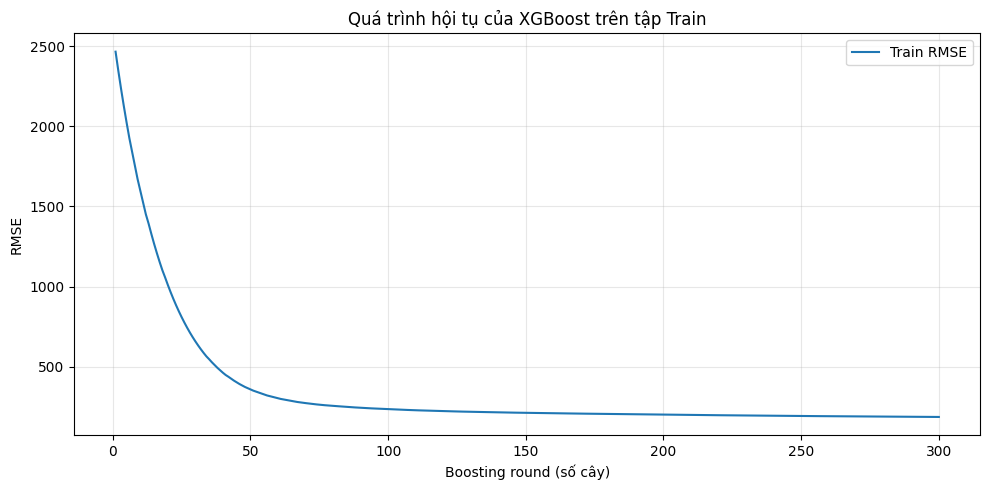

In [5]:
# Lấy RMSE của tập Train ở mỗi boosting round
evals_result = model.evals_result()
train_rmse = evals_result["validation_0"]["rmse"]

print(f"RMSE Train ban đầu (round 1): {train_rmse[0]:.4f}")
print(f"RMSE Train cuối cùng (round {len(train_rmse)}): {train_rmse[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_rmse) + 1), train_rmse, label="Train RMSE")
plt.xlabel("Boosting round (số cây)")
plt.ylabel("RMSE")
plt.title("Quá trình hội tụ của XGBoost trên tập Train")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Nhận xét quá trình huấn luyện

Sau khi chạy notebook, ghi nhận:
- Thời gian huấn luyện: giá trị được in ở Bước 4 (phụ thuộc cấu hình máy).
- RMSE ở vòng đầu và vòng cuối: giá trị được in ở Bước 5.
- Quan sát đồ thị: RMSE giảm nhanh ở giai đoạn đầu rồi giảm chậm/dần ổn định hay còn dao động.

**Cách diễn giải:** RMSE Train giảm cho thấy mô hình đang học các mẫu trong tập Train. Nếu RMSE tiếp tục giảm nhưng lỗi trên tập Validation/Test tăng, có thể xảy ra overfitting; cần đánh giá ở Bước 6. Không kết luận mô hình tổng quát tốt chỉ từ RMSE Train.

## 7. Kết quả bàn giao
- Mô hình đã fit: biến `model`.
- Thời gian huấn luyện: biến `training_seconds`.
- Lịch sử RMSE: biến `train_rmse`.
- Dữ liệu Train và danh sách đặc trưng: `X_train`, `y_train`, `feature_cols`.

Notebook chưa lưu mô hình ra file vì Bước 6 có thể tiếp tục dùng trực tiếp biến `model` trong cùng môi trường notebook/kernel.